In [1]:
!pip install autogluon.tabular pandas numpy -q
!pip install "git+https://github.com/FutureComputing4AI/EMBER2024.git" -q
!pip install --force-reinstall --no-deps "git+https://github.com/wbond/oscrypto.git" -q

In [2]:
import os
import re
import gc
import json
import time
import importlib.util

# ------------------------------------------------------------------
# Patch do oscrypto (detecção de versão do libcrypto)
# ------------------------------------------------------------------
spec = importlib.util.find_spec("oscrypto")
if spec is None:
    raise RuntimeError("oscrypto não está instalado.")

pkg_dir = list(spec.submodule_search_locations)[0]
cffi_path = os.path.join(pkg_dir, "_openssl", "_libcrypto_cffi.py")

with open(cffi_path, "r") as f:
    src = f.read()

if "LibraryNotFoundError('Error detecting the version of libcrypto')" in src:
    src = re.sub(
        r"^([ \t]*)raise LibraryNotFoundError\('Error detecting the version of libcrypto'\)",
        r"\1version_match = re.search(r'(\\d\\.\\d\\.\\d)', '3.0.0')",
        src,
        flags=re.MULTILINE,
    )
    with open(cffi_path, "w") as f:
        f.write(src)
    print("✓ Patch aplicado no oscrypto")
else:
    print("✓ oscrypto não precisa de patch")

# ------------------------------------------------------------------
# Patch do thrember: localizar SignedPEFile no signify instalado
# ------------------------------------------------------------------
sig_spec = importlib.util.find_spec("signify")
thr_spec = importlib.util.find_spec("thrember")
if sig_spec is None or thr_spec is None:
    raise RuntimeError("signify ou thrember não estão instalados.")

sig_dir = list(sig_spec.submodule_search_locations)[0]
sig_parent = os.path.dirname(sig_dir)

novo_modulo = None
for raiz, _, arquivos in os.walk(sig_dir):
    for nome in arquivos:
        if not nome.endswith(".py") or nome == "__init__.py":
            continue
        caminho = os.path.join(raiz, nome)
        with open(caminho, "r", errors="ignore") as f:
            if re.search(r"^class SignedPEFile\b", f.read(), flags=re.MULTILINE):
                rel = os.path.relpath(caminho, sig_parent)
                novo_modulo = rel[:-3].replace(os.sep, ".")
                break
    if novo_modulo:
        break

if novo_modulo is None:
    raise RuntimeError(
        "A classe SignedPEFile não existe nesta versão do signify. "
        "Instale uma versão compatível."
    )

print(f"SignedPEFile encontrado em: {novo_modulo}")

feat_path = os.path.join(list(thr_spec.submodule_search_locations)[0], "features.py")
with open(feat_path, "r") as f:
    feat_src = f.read()

linha_antiga = "from signify.authenticode import SignedPEFile"
linha_nova = f"from {novo_modulo} import SignedPEFile"

if linha_antiga in feat_src:
    feat_src = feat_src.replace(linha_antiga, linha_nova)
    with open(feat_path, "w") as f:
        f.write(feat_src)
    print("✓ Import corrigido no thrember")
else:
    print("✓ thrember não precisa de patch (ou já foi corrigido)")

# ------------------------------------------------------------------
# Imports
# ------------------------------------------------------------------
import numpy as np
import pandas as pd
import thrember
from autogluon.tabular import TabularPredictor, TabularDataset
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

print("✓ Imports efetuados com sucesso!")

# ------------------------------------------------------------------
# Configurações
# ------------------------------------------------------------------
RAIZ_DADOS = os.path.abspath("./ember2024_data")   # uma subpasta por tipo
RAIZ_MODELOS = os.path.abspath("./ag_models")      # uma subpasta por tipo
os.makedirs(RAIZ_DADOS, exist_ok=True)
os.makedirs(RAIZ_MODELOS, exist_ok=True)

TIME_LIMIT = 3 * 60 * 60
THRESHOLD = 0.3  # Limiar para classificar como malicioso
SEED = 0

# Limite de amostras de treino por tipo (None = usa o treino completo).
# Dot_Net tem 2568 features, então é o mais pesado em RAM.
N_TREINO = {
    "APK": None,
    "Dot_Net": 100_000,
    "PDF": None,
    "ELF": None,
}


def treinar_tipo(tipo):
    """Baixa, vetoriza, treina (máx. TIME_LIMIT) e avalia um tipo de arquivo."""
    print(f"\n{'=' * 60}\n  {tipo}\n{'=' * 60}")

    # Cada tipo vai para a sua própria pasta, para que
    # read_vectorized_features não misture tipos diferentes.
    destino = os.path.join(RAIZ_DADOS, tipo)
    os.makedirs(destino, exist_ok=True)

    ja_vetorizado = all(
        os.path.exists(os.path.join(destino, nome))
        for nome in ("X_train.dat", "y_train.dat", "X_test.dat", "y_test.dat")
    )
    if ja_vetorizado:
        print("Dados já vetorizados, pulando download.")
    else:
        print("Baixando dados...")
        thrember.download_dataset(destino, file_type=tipo)
        print("Vetorizando features...")
        thrember.create_vectorized_features(destino)

    # --- Carregar matrizes ---
    X_train, y_train = thrember.read_vectorized_features(destino, subset="train")
    X_test, y_test = thrember.read_vectorized_features(destino, subset="test")

    cols = [f"feat_{i}" for i in range(X_train.shape[1])]

    df_train = pd.DataFrame(X_train.astype(np.float32), columns=cols)
    df_train["label"] = y_train
    df_test = pd.DataFrame(X_test.astype(np.float32), columns=cols)
    df_test["label"] = y_test
    del X_train, X_test, y_train, y_test

    # Mantém só benigno (0) e malicioso (1)
    df_train = df_train[df_train["label"].isin([0, 1])].reset_index(drop=True)
    df_test = df_test[df_test["label"].isin([0, 1])].reset_index(drop=True)
    df_train["label"] = df_train["label"].astype(int)
    df_test["label"] = df_test["label"].astype(int)

    limite = N_TREINO.get(tipo)
    if limite is not None and len(df_train) > limite:
        df_train = df_train.sample(n=limite, random_state=SEED).reset_index(drop=True)

    print(f"Treino: {df_train.shape} | Teste: {df_test.shape}")
    print(df_train["label"].value_counts(normalize=True).round(4).to_dict())

    train_data = TabularDataset(df_train)
    test_data = TabularDataset(df_test)

    # --- Treino (máx. 1 hora) ---
    caminho_modelo = os.path.join(RAIZ_MODELOS, tipo)
    inicio = time.time()
    predictor = TabularPredictor(
        label="label",
        eval_metric="roc_auc",
        problem_type="binary",
        path=caminho_modelo,
    ).fit(
        train_data=train_data,
        presets="medium_quality",
        time_limit=TIME_LIMIT,
    )
    tempo_treino = time.time() - inicio

    # --- Avaliação ---
    y_true = test_data["label"].values
    proba = predictor.predict_proba(
        test_data.drop(columns=["label"]), as_multiclass=False
    ).values
    y_pred = (proba >= THRESHOLD).astype(int)

    fpr, tpr, _ = roc_curve(y_true, proba)
    metricas = {
        "tipo": tipo,
        "melhor_modelo": predictor.model_best,
        "n_treino": int(len(df_train)),
        "n_teste": int(len(df_test)),
        "tempo_treino_s": round(tempo_treino, 1),
        "threshold": THRESHOLD,
        "acuracia": accuracy_score(y_true, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "tpr_em_1pct_fpr": float(np.interp(0.01, fpr, tpr)),
    }

    # Salva em disco (sobrevive a reinício do kernel)
    with open(os.path.join(RAIZ_MODELOS, f"resultado_{tipo}.json"), "w") as f:
        json.dump(metricas, f, indent=2)

    print(f"\n✓ {tipo}: AUC={metricas['roc_auc']:.4f} | "
          f"acurácia={metricas['acuracia']:.4f} | "
          f"treino levou {tempo_treino / 60:.1f} min")

    # Libera memória antes do próximo tipo
    del df_train, df_test, train_data, test_data, predictor
    gc.collect()
    return metricas

✓ Patch aplicado no oscrypto
SignedPEFile encontrado em: signify.authenticode.signed_file.pe
✓ thrember não precisa de patch (ou já foi corrigido)


d:\Iniciação Científica\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Imports efetuados com sucesso!


In [3]:

import os
import re
import gc
import json
import time
import importlib.util

# ------------------------------------------------------------------
# Patch do oscrypto (detecção de versão do libcrypto)
# ------------------------------------------------------------------
spec = importlib.util.find_spec("oscrypto")
if spec is None:
    raise RuntimeError("oscrypto não está instalado.")

pkg_dir = list(spec.submodule_search_locations)[0]
cffi_path = os.path.join(pkg_dir, "_openssl", "_libcrypto_cffi.py")

with open(cffi_path, "r") as f:
    src = f.read()

if "LibraryNotFoundError('Error detecting the version of libcrypto')" in src:
    src = re.sub(
        r"^([ \t]*)raise LibraryNotFoundError\('Error detecting the version of libcrypto'\)",
        r"\1version_match = re.search(r'(\\d\\.\\d\\.\\d)', '3.0.0')",
        src,
        flags=re.MULTILINE,
    )

    with open(cffi_path, "w") as f:
        f.write(src)

    print("✓ Patch aplicado no oscrypto")
else:
    print("✓ oscrypto não precisa de patch")


# ------------------------------------------------------------------
# Patch do thrember: localizar SignedPEFile no signify instalado
# ------------------------------------------------------------------
sig_spec = importlib.util.find_spec("signify")
thr_spec = importlib.util.find_spec("thrember")

if sig_spec is None or thr_spec is None:
    raise RuntimeError("signify ou thrember não estão instalados.")

sig_dir = list(sig_spec.submodule_search_locations)[0]
sig_parent = os.path.dirname(sig_dir)

novo_modulo = None

for raiz, _, arquivos in os.walk(sig_dir):
    for nome in arquivos:

        if not nome.endswith(".py") or nome == "__init__.py":
            continue

        caminho = os.path.join(raiz, nome)

        with open(caminho, "r", errors="ignore") as f:
            if re.search(
                r"^class SignedPEFile\b",
                f.read(),
                flags=re.MULTILINE
            ):
                rel = os.path.relpath(caminho, sig_parent)
                novo_modulo = rel[:-3].replace(os.sep, ".")
                break

    if novo_modulo:
        break

if novo_modulo is None:
    raise RuntimeError(
        "A classe SignedPEFile não existe nesta versão do signify. "
        "Instale uma versão compatível."
    )

print(f"SignedPEFile encontrado em: {novo_modulo}")

feat_path = os.path.join(
    list(thr_spec.submodule_search_locations)[0],
    "features.py"
)

with open(feat_path, "r") as f:
    feat_src = f.read()

linha_antiga = "from signify.authenticode import SignedPEFile"
linha_nova = f"from {novo_modulo} import SignedPEFile"

if linha_antiga in feat_src:

    feat_src = feat_src.replace(linha_antiga, linha_nova)

    with open(feat_path, "w") as f:
        f.write(feat_src)

    print("✓ Import corrigido no thrember")

else:
    print("✓ thrember não precisa de patch (ou já foi corrigido)")


# ------------------------------------------------------------------
# Imports
# ------------------------------------------------------------------
import numpy as np
import pandas as pd
import thrember

from autogluon.tabular import TabularPredictor, TabularDataset

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

print("✓ Imports efetuados com sucesso!")


# ------------------------------------------------------------------
# Verificação da versão do AutoGluon
# ------------------------------------------------------------------
if not hasattr(TabularPredictor, "fit_extra"):
    raise RuntimeError(
        "Sua versão do AutoGluon não possui fit_extra(). "
        "É necessária a versão 1.2.0 ou superior."
    )

print("✓ AutoGluon possui suporte ao fit_extra()")


# ------------------------------------------------------------------
# Configurações
# ------------------------------------------------------------------
RAIZ_DADOS = os.path.abspath("./ember2024_data")
RAIZ_MODELOS = os.path.abspath("./ag_models")

os.makedirs(RAIZ_DADOS, exist_ok=True)
os.makedirs(RAIZ_MODELOS, exist_ok=True)

# 3 horas por tipo de arquivo (10.800 segundos)
TIME_LIMIT = 3 * 60 * 60

# Limiar para classificar como malicioso
THRESHOLD = 0.3

SEED = 0

# Limite de amostras de treino por tipo.
# None = utiliza o conjunto completo.
N_TREINO = {
    "APK": None,
    "Dot_Net": 100_000,
    "PDF": None,
    "ELF": None,
}


# ------------------------------------------------------------------
# Função de treinamento
# ------------------------------------------------------------------
def treinar_tipo(tipo):

    """Baixa, vetoriza, treina por pelo menos TIME_LIMIT e avalia."""

    print(f"\n{'=' * 60}\n  {tipo}\n{'=' * 60}")

    # --------------------------------------------------------------
    # Preparação dos dados
    # --------------------------------------------------------------
    destino = os.path.join(RAIZ_DADOS, tipo)
    os.makedirs(destino, exist_ok=True)

    ja_vetorizado = all(
        os.path.exists(os.path.join(destino, nome))
        for nome in (
            "X_train.dat",
            "y_train.dat",
            "X_test.dat",
            "y_test.dat"
        )
    )

    if ja_vetorizado:

        print("Dados já vetorizados, pulando download.")

    else:

        print("Baixando dados...")

        thrember.download_dataset(
            destino,
            file_type=tipo
        )

        print("Vetorizando features...")

        thrember.create_vectorized_features(destino)

    # --------------------------------------------------------------
    # Carregar matrizes
    # --------------------------------------------------------------
    X_train, y_train = thrember.read_vectorized_features(
        destino,
        subset="train"
    )

    X_test, y_test = thrember.read_vectorized_features(
        destino,
        subset="test"
    )

    cols = [
        f"feat_{i}"
        for i in range(X_train.shape[1])
    ]

    df_train = pd.DataFrame(
        X_train.astype(np.float32),
        columns=cols
    )

    df_train["label"] = y_train

    df_test = pd.DataFrame(
        X_test.astype(np.float32),
        columns=cols
    )

    df_test["label"] = y_test

    del X_train, X_test, y_train, y_test

    gc.collect()

    # --------------------------------------------------------------
    # Manter somente benignos (0) e maliciosos (1)
    # --------------------------------------------------------------
    df_train = df_train[
        df_train["label"].isin([0, 1])
    ].reset_index(drop=True)

    df_test = df_test[
        df_test["label"].isin([0, 1])
    ].reset_index(drop=True)

    df_train["label"] = df_train["label"].astype(int)
    df_test["label"] = df_test["label"].astype(int)

    # --------------------------------------------------------------
    # Limitar quantidade de amostras de treinamento
    # --------------------------------------------------------------
    limite = N_TREINO.get(tipo)

    if limite is not None and len(df_train) > limite:

        df_train = df_train.sample(
            n=limite,
            random_state=SEED
        ).reset_index(drop=True)

    print(f"Treino: {df_train.shape} | Teste: {df_test.shape}")

    print(
        df_train["label"]
        .value_counts(normalize=True)
        .round(4)
        .to_dict()
    )

    train_data = TabularDataset(df_train)
    test_data = TabularDataset(df_test)

    # --------------------------------------------------------------
    # Treinamento inicial
    # --------------------------------------------------------------
    caminho_modelo = os.path.join(RAIZ_MODELOS, tipo)

    # O cronômetro começa antes do treinamento inicial.
    inicio_treinamento = time.monotonic()

    prazo_treinamento = inicio_treinamento + TIME_LIMIT

    print(
        f"\nIniciando treinamento de {tipo}."
        f"\nTempo mínimo configurado: {TIME_LIMIT / 3600:.1f} horas."
    )

    predictor = TabularPredictor(
        label="label",
        eval_metric="roc_auc",
        problem_type="binary",
        path=caminho_modelo,
    ).fit(
        train_data=train_data,
        presets="medium_quality",
        time_limit=TIME_LIMIT,
    )

    print("\n✓ Treinamento inicial finalizado.")

    print(
        f"Modelos disponíveis: {len(predictor.model_names())}"
    )

    # --------------------------------------------------------------
    # Configurações dos treinamentos complementares
    # --------------------------------------------------------------
    # Cada configuração produz um novo modelo LightGBM.
    # Os parâmetros são modificados entre os ciclos.

    configuracoes_gbm = [

        {
            "num_boost_round": 3000,
            "learning_rate": 0.03,
            "num_leaves": 31,
            "feature_fraction": 0.80,
            "min_data_in_leaf": 30,
            "extra_trees": False,
        },

        {
            "num_boost_round": 3000,
            "learning_rate": 0.02,
            "num_leaves": 63,
            "feature_fraction": 0.85,
            "min_data_in_leaf": 40,
            "extra_trees": True,
        },

        {
            "num_boost_round": 3000,
            "learning_rate": 0.05,
            "num_leaves": 127,
            "feature_fraction": 0.70,
            "min_data_in_leaf": 50,
            "extra_trees": False,
        },

        {
            "num_boost_round": 3000,
            "learning_rate": 0.01,
            "num_leaves": 63,
            "feature_fraction": 1.00,
            "min_data_in_leaf": 20,
            "extra_trees": True,
        },

        {
            "num_boost_round": 3000,
            "learning_rate": 0.03,
            "num_leaves": 127,
            "feature_fraction": 0.90,
            "min_data_in_leaf": 80,
            "extra_trees": False,
        },
    ]

    # --------------------------------------------------------------
    # Treinamento complementar
    # --------------------------------------------------------------
    ciclo = 0
    falhas_consecutivas = 0

    while True:

        tempo_restante = (
            prazo_treinamento - time.monotonic()
        )

        # Finaliza quando atingir o prazo de 3 horas.
        if tempo_restante <= 0:
            break

        ciclo += 1

        indice_config = (
            (ciclo - 1) % len(configuracoes_gbm)
        )

        # Copiar configuração para não alterar a lista original.
        parametros_gbm = dict(
            configuracoes_gbm[indice_config]
        )

        # Identificador exclusivo para cada novo modelo.
        parametros_gbm["ag_args"] = {
            "name_suffix": f"Extra{ciclo:04d}"
        }

        modelos_anteriores = set(
            predictor.model_names()
        )

        print(
            f"\n{'-' * 60}"
            f"\nTreinamento complementar: {ciclo}"
            f"\nConfiguração: {indice_config + 1}"
            f"\nTempo restante: {tempo_restante / 60:.1f} minutos"
            f"\n{'-' * 60}"
        )

        # Adiciona novos modelos ao preditor existente.
        predictor.fit_extra(
            hyperparameters={
                "GBM": [parametros_gbm]
            },
            time_limit=max(
                1,
                int(np.ceil(tempo_restante))
            ),
            fit_weighted_ensemble=True,
            fit_strategy="sequential",
        )

        modelos_atuais = set(
            predictor.model_names()
        )

        novos_modelos = (
            modelos_atuais - modelos_anteriores
        )

        if novos_modelos:

            falhas_consecutivas = 0

            print(
                f"✓ Treinamento complementar {ciclo} concluído."
                f"\nNovos modelos adicionados: {len(novos_modelos)}"
            )

            for nome_modelo in sorted(novos_modelos):
                print(f"  - {nome_modelo}")

        else:

            falhas_consecutivas += 1

            print(
                f"⚠ Nenhum novo modelo foi adicionado."
                f"\nFalhas consecutivas: {falhas_consecutivas}"
            )

            # Não continua silenciosamente se os modelos
            # complementares estiverem falhando repetidamente.
            if time.monotonic() < prazo_treinamento:
                if falhas_consecutivas >= 3:
                    raise RuntimeError(
                        f"{tipo}: três treinamentos complementares "
                        "consecutivos não adicionaram modelos. "
                        "Verifique os logs do AutoGluon."
                    )

        gc.collect()

    # --------------------------------------------------------------
    # Encerramento do treinamento
    # --------------------------------------------------------------
    tempo_treino = (
        time.monotonic() - inicio_treinamento
    )

    print(
        f"\n{'=' * 60}"
        f"\n✓ Treinamento de {tipo} finalizado."
        f"\nTempo total: {tempo_treino / 3600:.2f} horas"
        f"\nQuantidade de modelos: {len(predictor.model_names())}"
        f"\nMelhor modelo: {predictor.model_best}"
        f"\n{'=' * 60}"
    )

    # --------------------------------------------------------------
    # Avaliação
    # --------------------------------------------------------------
    y_true = test_data["label"].values

    # Probabilidade da classe positiva (malicioso = 1).
    proba = np.asarray(
        predictor.predict_proba(
            test_data.drop(columns=["label"]),
            as_multiclass=False
        )
    ).reshape(-1)

    # Aplicar limiar de classificação.
    y_pred = (proba >= THRESHOLD).astype(int)

    # Verificar se as duas classes estão presentes.
    if len(np.unique(y_true)) < 2:
        raise ValueError(
            f"{tipo}: o conjunto de teste possui somente uma classe. "
            "Não é possível calcular ROC-AUC."
        )

    # Curva ROC.
    fpr, tpr, _ = roc_curve(y_true, proba)

    # --------------------------------------------------------------
    # Métricas
    # --------------------------------------------------------------
    metricas = {

        "tipo": tipo,

        "melhor_modelo": predictor.model_best,

        "quantidade_modelos": len(predictor.model_names()),

        "n_treino": int(len(df_train)),

        "n_teste": int(len(df_test)),

        "tempo_treino_s": round(tempo_treino, 1),

        "threshold": THRESHOLD,

        "acuracia": float(
            accuracy_score(y_true, y_pred)
        ),

        "acuracia_balanceada": float(
            balanced_accuracy_score(y_true, y_pred)
        ),

        "precisao": float(
            precision_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "f1": float(
            f1_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "roc_auc": float(
            roc_auc_score(y_true, proba)
        ),

        "tpr_em_1pct_fpr": float(
            np.interp(0.01, fpr, tpr)
        ),
    }

    # --------------------------------------------------------------
    # Salvar resultados
    # --------------------------------------------------------------
    caminho_resultado = os.path.join(
        RAIZ_MODELOS,
        f"resultado_{tipo}.json"
    )

    with open(caminho_resultado, "w", encoding="utf-8") as f:
        json.dump(
            metricas,
            f,
            indent=2,
            ensure_ascii=False
        )

    print(
        f"\n✓ {tipo}:"
        f"\nAUC = {metricas['roc_auc']:.4f}"
        f"\nAcurácia = {metricas['acuracia']:.4f}"
        f"\nPrecisão = {metricas['precisao']:.4f}"
        f"\nRecall = {metricas['recall']:.4f}"
        f"\nF1 = {metricas['f1']:.4f}"
        f"\nTempo de treinamento = {tempo_treino / 3600:.2f} horas"
        f"\nResultado salvo em: {caminho_resultado}"
    )

    # --------------------------------------------------------------
    # Liberar memória
    # --------------------------------------------------------------
    del df_train
    del df_test
    del train_data
    del test_data
    del predictor

    gc.collect()

    return metricas


✓ oscrypto não precisa de patch
SignedPEFile encontrado em: signify.authenticode.signed_file.pe
✓ thrember não precisa de patch (ou já foi corrigido)
✓ Imports efetuados com sucesso!
✓ AutoGluon possui suporte ao fit_extra()


In [4]:
treinar_tipo("APK")


  APK
Dados já vetorizados, pulando download.


Treino: (416000, 2569) | Teste: (96000, 2569)
{0: 0.5, 1: 0.5}

Iniciando treinamento de APK.
Tempo mínimo configurado: 3.0 horas.


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       4.49 GB / 15.84 GB (28.3%)
Disk Space Avail:   1832.47 GB / 2793.86 GB (65.6%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 10800s
AutoGluon will save models to "d:\Iniciação Científica\ag_models\APK"
Train Data Rows:    416000
Train Data Columns: 2568
Label Column:       label
Problem Type:       binary
Preprocessing data...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    8344.04 MB
	Train Data (Original)  Memory Usa

[1000]	valid_set's binary_logloss: 0.144136
[2000]	valid_set's binary_logloss: 0.108815
[3000]	valid_set's binary_logloss: 0.0848687
[4000]	valid_set's binary_logloss: 0.0664275
[5000]	valid_set's binary_logloss: 0.0520144
[6000]	valid_set's binary_logloss: 0.0400247
[7000]	valid_set's binary_logloss: 0.030173
[8000]	valid_set's binary_logloss: 0.0227231
[9000]	valid_set's binary_logloss: 0.0172434
[10000]	valid_set's binary_logloss: 0.0131905


	1.0	 = Validation score   (roc_auc)
	2366.3s	 = Training   runtime
	0.48s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 8358.18s of the 8358.17s of remaining time.
	Fitting with cpus=10, gpus=0, mem=6.0/9.3 GB


[1000]	valid_set's binary_logloss: 0.122461
[2000]	valid_set's binary_logloss: 0.0806863
[3000]	valid_set's binary_logloss: 0.0527783
[4000]	valid_set's binary_logloss: 0.0335159
[5000]	valid_set's binary_logloss: 0.0210801
[6000]	valid_set's binary_logloss: 0.0136241
[7000]	valid_set's binary_logloss: 0.00922286
[8000]	valid_set's binary_logloss: 0.00651661
[9000]	valid_set's binary_logloss: 0.00499016
[10000]	valid_set's binary_logloss: 0.00408311


	1.0	 = Validation score   (roc_auc)
	1985.77s	 = Training   runtime
	0.45s	 = Validation runtime
Fitting model: RandomForestGini ... Training model for up to 6371.30s of the 6371.29s of remaining time.
	To force training the model, specify the model hyperparameter "ag.max_memory_usage_ratio" to a larger value (currently 1.0, set to >=1.38 to avoid the error)
		To set the same value for all models, do the following when calling predictor.fit: `predictor.fit(..., ag_args_fit={"ag.max_memory_usage_ratio": VALUE})`
		Setting "ag.max_memory_usage_ratio" to values above 1 may result in out-of-memory errors. You may consider using a machine with more memory as a safer alternative.
	Not enough memory to train RandomForestGini... Skipping this model.
Fitting model: RandomForestEntr ... Training model for up to 6365.93s of the 6365.92s of remaining time.
	To force training the model, specify the model hyperparameter "ag.max_memory_usage_ratio" to a larger value (currently 1.0, set to >=1.38 to 


✓ Treinamento inicial finalizado.
Modelos disponíveis: 5

✓ Treinamento de APK finalizado.
Tempo total: 3.01 horas
Quantidade de modelos: 5
Melhor modelo: WeightedEnsemble_L2

✓ APK:
AUC = 0.9906
Acurácia = 0.9536
Precisão = 0.9624
Recall = 0.9442
F1 = 0.9532
Tempo de treinamento = 3.01 horas
Resultado salvo em: d:\Iniciação Científica\ag_models\resultado_APK.json


{'tipo': 'APK',
 'melhor_modelo': 'WeightedEnsemble_L2',
 'quantidade_modelos': 5,
 'n_treino': 416000,
 'n_teste': 96000,
 'tempo_treino_s': 10844.3,
 'threshold': 0.3,
 'acuracia': 0.9536458333333333,
 'acuracia_balanceada': 0.9536458333333333,
 'precisao': 0.962373126088249,
 'recall': 0.9442083333333333,
 'f1': 0.9532041979515006,
 'roc_auc': 0.990608373263889,
 'tpr_em_1pct_fpr': 0.8710833333333333}

In [5]:
treinar_tipo("Dot_Net")


  Dot_Net
Dados já vetorizados, pulando download.


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       10.53 GB / 15.84 GB (66.5%)
Disk Space Avail:   1832.45 GB / 2793.86 GB (65.6%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'


Treino: (100000, 2569) | Teste: (120000, 2569)
{0: 0.5015, 1: 0.4985}

Iniciando treinamento de Dot_Net.
Tempo mínimo configurado: 3.0 horas.


Beginning AutoGluon training ... Time limit = 10800s
AutoGluon will save models to "d:\Iniciação Científica\ag_models\Dot_Net"
Train Data Rows:    100000
Train Data Columns: 2568
Label Column:       label
Problem Type:       binary
Preprocessing data...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    10875.03 MB
	Train Data (Original)  Memory Usage: 979.61 MB (9.0% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 801 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 

[1000]	valid_set's binary_logloss: 0.0523567


	0.9983	 = Validation score   (roc_auc)
	131.29s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 10657.51s of the 10657.51s of remaining time.
	Fitting with cpus=10, gpus=0, mem=2.3/9.6 GB


... (96 outputs left out)

✓ Treinamento complementar 29 concluído.
Novos modelos adicionados: 2
  - LightGBMExtra0029
  - WeightedEnsemble_30_L2

------------------------------------------------------------
Treinamento complementar: 30
Configuração: 5
Tempo restante: 1.3 minutos
------------------------------------------------------------


	Fitting with cpus=10, gpus=0, mem=2.9/9.7 GB
	Ran out of time, early stopping on iteration 320. Best iteration is:
	[320]	valid_set's binary_logloss: 0.0554672
	0.9979	 = Validation score   (roc_auc)
	76.18s	 = Training   runtime
	0.03s	 = Validation runtime
Fitting model: WeightedEnsemble_31_L2 ... Training model for up to 76.00s of the -0.29s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=16, gpus=0, mem=0.0/9.9 GB
	Ensemble Weights: {'LightGBMExtra0030': 1.0}
	0.9979	 = Validation score   (roc_auc)
	0.0s	 = Training   runtime
	0.0s	 = Validation runtime
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("d:\Iniciação Científica\ag_models\Dot_Net")


✓ Treinamento complementar 30 concluído.
Novos modelos adicionados: 2
  - LightGBMExtra0030
  - WeightedEnsemble_31_L2

✓ Treinamento de Dot_Net finalizado.
Tempo total: 3.00 horas
Quantidade de modelos: 72
Melhor modelo: WeightedEnsemble_L2

✓ Dot_Net:
AUC = 0.9974
Acurácia = 0.9742
Precisão = 0.9633
Recall = 0.9859
F1 = 0.9745
Tempo de treinamento = 3.00 horas
Resultado salvo em: d:\Iniciação Científica\ag_models\resultado_Dot_Net.json


{'tipo': 'Dot_Net',
 'melhor_modelo': 'WeightedEnsemble_L2',
 'quantidade_modelos': 72,
 'n_treino': 100000,
 'n_teste': 120000,
 'tempo_treino_s': 10800.8,
 'threshold': 0.3,
 'acuracia': 0.9741666666666666,
 'acuracia_balanceada': 0.9741666666666666,
 'precisao': 0.9632645085651013,
 'recall': 0.9859333333333333,
 'f1': 0.9744671037459229,
 'roc_auc': 0.9974236722222223,
 'tpr_em_1pct_fpr': 0.9417333333333333}

In [6]:
treinar_tipo("PDF")


  PDF
Dados já vetorizados, pulando download.


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       10.43 GB / 15.84 GB (65.8%)
Disk Space Avail:   1832.18 GB / 2793.86 GB (65.6%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 10800s
AutoGluon will save models to "d:\Iniciação Científica\ag_models\PDF"
Train Data Rows:    104000
Train Data Columns: 2568
Label Column:       label
Problem Type:       binary
Preprocessing data...


Treino: (104000, 2569) | Teste: (24000, 2569)
{1: 0.5, 0: 0.5}

Iniciando treinamento de PDF.
Tempo mínimo configurado: 3.0 horas.


Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    10646.43 MB
	Train Data (Original)  Memory Usage: 1018.80 MB (9.6% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 1 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Useless Original Features (Count: 1878): ['feat_2', 'feat_629', 'feat_630', 'feat_631', 'feat_633', 'feat_678', 'feat_696', 'feat_697', 'feat_698', 'feat_699', 'feat_700', 'feat_701', 'feat_702', 

[1000]	valid_set's binary_logloss: 0.00528353
[2000]	valid_set's binary_logloss: 0.00329235


	1.0	 = Validation score   (roc_auc)
	136.14s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 10658.25s of the 10658.25s of remaining time.
	Fitting with cpus=10, gpus=0, mem=1.6/9.2 GB


... (150 outputs left out)

[1000]	valid_set's binary_logloss: 0.00959218


	Ran out of time, early stopping on iteration 1028. Best iteration is:
	[1028]	valid_set's binary_logloss: 0.00910774
	1.0	 = Validation score   (roc_auc)
	101.13s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: WeightedEnsemble_38_L2 ... Training model for up to 101.00s of the -0.27s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=16, gpus=0, mem=0.0/10.5 GB
	Ensemble Weights: {'LightGBMExtra0037': 1.0}
	1.0	 = Validation score   (roc_auc)
	0.0s	 = Training   runtime
	0.0s	 = Validation runtime
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("d:\Iniciação Científica\ag_models\PDF")


✓ Treinamento complementar 37 concluído.
Novos modelos adicionados: 2
  - LightGBMExtra0037
  - WeightedEnsemble_38_L2

✓ Treinamento de PDF finalizado.
Tempo total: 3.00 horas
Quantidade de modelos: 86
Melhor modelo: WeightedEnsemble_L2

✓ PDF:
AUC = 0.9907
Acurácia = 0.9601
Precisão = 0.9897
Recall = 0.9298
F1 = 0.9588
Tempo de treinamento = 3.00 horas
Resultado salvo em: d:\Iniciação Científica\ag_models\resultado_PDF.json


{'tipo': 'PDF',
 'melhor_modelo': 'WeightedEnsemble_L2',
 'quantidade_modelos': 86,
 'n_treino': 104000,
 'n_teste': 24000,
 'tempo_treino_s': 10800.9,
 'threshold': 0.3,
 'acuracia': 0.9600833333333333,
 'acuracia_balanceada': 0.9600833333333333,
 'precisao': 0.9897108390988114,
 'recall': 0.9298333333333333,
 'f1': 0.9588381885365644,
 'roc_auc': 0.9907480972222222,
 'tpr_em_1pct_fpr': 0.9315}

In [7]:
treinar_tipo("ELF")


  ELF
Dados já vetorizados, pulando download.


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       10.42 GB / 15.84 GB (65.8%)
Disk Space Avail:   1831.69 GB / 2793.86 GB (65.6%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'
Beginning AutoGluon training ... Time limit = 10800s
AutoGluon will save models to "d:\Iniciação Científica\ag_models\ELF"
Train Data Rows:    52000
Train Data Columns: 2568
Label Column:       label
Problem Type:       binary
Preprocessing data...


Treino: (52000, 2569) | Teste: (12000, 2569)
{0: 0.5, 1: 0.5}

Iniciando treinamento de ELF.
Tempo mínimo configurado: 3.0 horas.


Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    10693.59 MB
	Train Data (Original)  Memory Usage: 509.40 MB (4.8% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 1 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Useless Original Features (Count: 1879): ['feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_629', 'feat_631', 'feat_696', 'feat_697', 'feat_698', 'feat_699', 'feat_700', 'feat_701', 'feat_702

[1000]	valid_set's binary_logloss: 0.00375674


	1.0	 = Validation score   (roc_auc)
	79.62s	 = Training   runtime
	0.04s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 10717.37s of the 10717.37s of remaining time.
	Fitting with cpus=10, gpus=0, mem=0.9/10.6 GB


... (242 outputs left out)

✓ Treinamento complementar 75 concluído.
Novos modelos adicionados: 2
  - LightGBMExtra0075
  - WeightedEnsemble_76_L2

------------------------------------------------------------
Treinamento complementar: 76
Configuração: 1
Tempo restante: 0.1 minutos
------------------------------------------------------------


Fitting 1 L1 models, fit_strategy="sequential" ...
Fitting model: LightGBMExtra0076 ... Training model for up to 6.00s of the 6.00s of remaining time.
	Fitting with cpus=10, gpus=0, mem=0.9/10.1 GB
	Ran out of time, early stopping on iteration 91. Best iteration is:
	[91]	valid_set's binary_logloss: 0.140687
	0.994	 = Validation score   (roc_auc)
	6.06s	 = Training   runtime
	0.01s	 = Validation runtime
Fitting model: WeightedEnsemble_77_L2 ... Training model for up to 6.00s of the -0.16s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=16, gpus=0, mem=0.0/10.5 GB
	Ensemble Weights: {'LightGBMExtra0076': 1.0}
	0.994	 = Validation score   (roc_auc)
	0.0s	 = Training   runtime
	0.0s	 = Validation runtime
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("d:\Iniciação Científica\ag_models\ELF")


✓ Treinamento complementar 76 concluído.
Novos modelos adicionados: 2
  - LightGBMExtra0076
  - WeightedEnsemble_77_L2

✓ Treinamento de ELF finalizado.
Tempo total: 3.00 horas
Quantidade de modelos: 164
Melhor modelo: WeightedEnsemble_L2

✓ ELF:
AUC = 0.9928
Acurácia = 0.9620
Precisão = 0.9442
Recall = 0.9820
F1 = 0.9627
Tempo de treinamento = 3.00 horas
Resultado salvo em: d:\Iniciação Científica\ag_models\resultado_ELF.json


{'tipo': 'ELF',
 'melhor_modelo': 'WeightedEnsemble_L2',
 'quantidade_modelos': 164,
 'n_treino': 52000,
 'n_teste': 12000,
 'tempo_treino_s': 10801.5,
 'threshold': 0.3,
 'acuracia': 0.962,
 'acuracia_balanceada': 0.962,
 'precisao': 0.9442307692307692,
 'recall': 0.982,
 'f1': 0.9627450980392157,
 'roc_auc': 0.9927640555555556,
 'tpr_em_1pct_fpr': 0.913}

In [8]:
ordem = ["APK", "Dot_Net", "PDF", "ELF"]
linhas = []
for tipo in ordem:
    arq = os.path.join(RAIZ_MODELOS, f"resultado_{tipo}.json")
    if os.path.exists(arq):
        with open(arq) as f:
            linhas.append(json.load(f))
    else:
        print(f"(sem resultado para {tipo}; rode a célula de treino correspondente)")

df_resultados = pd.DataFrame(linhas).set_index("tipo")
colunas_metricas = [
    "acuracia", "acuracia_balanceada", "precisao",
    "recall", "f1", "roc_auc", "tpr_em_1pct_fpr",
]
df_resultados[colunas_metricas] = df_resultados[colunas_metricas].round(4)

try:
    display(df_resultados)  # Jupyter / VS Code interativo
except NameError:
    print(df_resultados.to_string())

# Opcional: exportar para Excel
# df_resultados.to_excel("Resultados_por_tipo.xlsx")

,melhor_modelo,quantidade_modelos,n_treino,n_teste,tempo_treino_s,threshold,acuracia,acuracia_balanceada,precisao,recall,f1,roc_auc,tpr_em_1pct_fpr
tipo,,,,,,,,,,,,,
APK,WeightedEnsemble_L2,5,416000,96000,10844.3,0.3,0.9536,0.9536,0.9624,0.9442,0.9532,0.9906,0.8711
Dot_Net,WeightedEnsemble_L2,72,100000,120000,10800.8,0.3,0.9742,0.9742,0.9633,0.9859,0.9745,0.9974,0.9417
PDF,WeightedEnsemble_L2,86,104000,24000,10800.9,0.3,0.9601,0.9601,0.9897,0.9298,0.9588,0.9907,0.9315
ELF,WeightedEnsemble_L2,164,52000,12000,10801.5,0.3,0.9620,0.9620,0.9442,0.9820,0.9627,0.9928,0.9130


In [9]:
TIPOS = ["APK", "Dot_Net", "PDF", "ELF"]
 
# Máximo de amostras de treino por tipo (None = tudo). Mantém a RAM sob controle
# e evita que APK/Dot_Net (muito maiores) dominem o treino.
N_TREINO_POR_TIPO = {"APK": 50_000, "Dot_Net": 50_000, "PDF": None, "ELF": None}
TIME_LIMIT_COMBINADO = TIME_LIMIT          # 1 hora (limite do fit)
USAR_TIPO_COMO_FEATURE = True              # coluna categórica "tipo_arquivo"
rng = np.random.default_rng(SEED)
 
 
def carregar_tipo(tipo):
    destino = os.path.join(RAIZ_DADOS, tipo)
    try:
        Xtr, ytr = thrember.read_vectorized_features(destino, subset="train")
        Xte, yte = thrember.read_vectorized_features(destino, subset="test")
    except Exception:
        print(f"{tipo}: dados vetorizados não encontrados, baixando...")
        os.makedirs(destino, exist_ok=True)
        thrember.download_dataset(destino, file_type=tipo)
        thrember.create_vectorized_features(destino)
        Xtr, ytr = thrember.read_vectorized_features(destino, subset="train")
        Xte, yte = thrember.read_vectorized_features(destino, subset="test")
    return Xtr, np.asarray(ytr), Xte, np.asarray(yte)
 
 
def montar_df(X, y, tipo, dim, limite=None):
    idx = np.where(np.isin(y, [0, 1]))[0]          # só benigno (0) e malicioso (1)
    if limite is not None and len(idx) > limite:
        idx = np.sort(rng.choice(idx, size=limite, replace=False))
    arr = np.zeros((len(idx), dim), dtype=np.float32)   # completa com zeros se faltar coluna
    arr[:, : X.shape[1]] = np.asarray(X[idx], dtype=np.float32)
    df = pd.DataFrame(arr, columns=[f"feat_{i}" for i in range(dim)])
    if USAR_TIPO_COMO_FEATURE:
        df["tipo_arquivo"] = pd.Categorical([tipo] * len(df), categories=TIPOS)
    df["label"] = y[idx].astype(int)
    return df
 
 
def metricas_basicas(y_true, proba):
    y_pred = (proba >= THRESHOLD).astype(int)
    fpr, tpr, _ = roc_curve(y_true, proba)
    return {
        "n_teste": int(len(y_true)),
        "threshold": THRESHOLD,
        "acuracia": accuracy_score(y_true, y_pred),
        "acuracia_balanceada": balanced_accuracy_score(y_true, y_pred),
        "precisao": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "tpr_em_1pct_fpr": float(np.interp(0.01, fpr, tpr)),
    }
 
 
# --- Carregar os 4 tipos (memmap/arrays) e definir a dimensão comum ---
dados = {t: carregar_tipo(t) for t in TIPOS}
dim = max(d[0].shape[1] for d in dados.values())
print("Dimensões por tipo:", {t: d[0].shape[1] for t, d in dados.items()}, "-> usando", dim)
 
# --- Treino combinado ---
partes = [
    montar_df(dados[t][0], dados[t][1], t, dim, N_TREINO_POR_TIPO.get(t)) for t in TIPOS
]
df_train = pd.concat(partes, ignore_index=True)
del partes
gc.collect()
print(f"Treino combinado: {df_train.shape}")
print(df_train.groupby("tipo_arquivo", observed=True)["label"].agg(["count", "mean"])
      if USAR_TIPO_COMO_FEATURE else df_train["label"].value_counts(normalize=True))
 
inicio = time.time()
predictor = TabularPredictor(
    label="label",
    eval_metric="roc_auc",
    problem_type="binary",
    path=os.path.join(RAIZ_MODELOS, "Combinado"),
).fit(
    train_data=TabularDataset(df_train),
    presets="medium_quality",
    time_limit=TIME_LIMIT_COMBINADO,
)
tempo_treino = time.time() - inicio
n_treino = len(df_train)
del df_train
gc.collect()
 
# --- Avaliação no test oficial: por tipo e geral ---
linhas, todos_y, todos_p = [], [], []
for t in TIPOS:
    df_t = montar_df(dados[t][2], dados[t][3], t, dim)
    y_t = df_t["label"].values
    p_t = predictor.predict_proba(df_t.drop(columns=["label"]), as_multiclass=False).values
    linhas.append({"tipo": t, **metricas_basicas(y_t, p_t)})
    todos_y.append(y_t)
    todos_p.append(p_t)
    del df_t
    gc.collect()
 
linhas.append({"tipo": "GERAL (4 tipos)",
               **metricas_basicas(np.concatenate(todos_y), np.concatenate(todos_p))})
 
df_combinado = pd.DataFrame(linhas).set_index("tipo")
colunas = ["acuracia", "acuracia_balanceada", "precisao", "recall", "f1", "roc_auc", "tpr_em_1pct_fpr"]
df_combinado[colunas] = df_combinado[colunas].round(4)
df_combinado.to_csv(os.path.join(RAIZ_MODELOS, "resultado_Combinado.csv"))
 
print(f"\n✓ Modelo combinado: melhor modelo = {predictor.model_best} | "
      f"{n_treino} amostras de treino | treino levou {tempo_treino / 60:.1f} min")
try:
    display(df_combinado)
except NameError:
    print(df_combinado.to_string())

Dimensões por tipo: {'APK': 2568, 'Dot_Net': 2568, 'PDF': 2568, 'ELF': 2568} -> usando 2568


Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.17
Operating System:   Windows
Platform Machine:   AMD64
Platform Version:   10.0.26200
CPU Count:          16
Pytorch Version:    2.13.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       3.52 GB / 15.84 GB (22.2%)
Disk Space Avail:   1830.91 GB / 2793.86 GB (65.5%)
Presets specified: ['medium_quality']
Using hyperparameters preset: hyperparameters='default'


Treino combinado: (256000, 2570)
               count     mean
tipo_arquivo                 
APK            50000  0.50026
Dot_Net        50000  0.50100
PDF           104000  0.50000
ELF            52000  0.50000


Beginning AutoGluon training ... Time limit = 10800s
AutoGluon will save models to "d:\Iniciação Científica\ag_models\Combinado"
Train Data Rows:    256000
Train Data Columns: 2569
Label Column:       label
Problem Type:       binary
Preprocessing data...
Selected class <--> label mapping:  class 1 = 1, class 0 = 0
Using Feature Generators to preprocess the data ...
Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    5725.97 MB
	Train Data (Original)  Memory Usage: 2508.06 MB (43.8% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 799 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMi

[1000]	valid_set's binary_logloss: 0.0839178
[2000]	valid_set's binary_logloss: 0.0616155
[3000]	valid_set's binary_logloss: 0.0519667
[4000]	valid_set's binary_logloss: 0.0476902
[5000]	valid_set's binary_logloss: 0.0447528
[6000]	valid_set's binary_logloss: 0.0442174
[7000]	valid_set's binary_logloss: 0.0441672
[8000]	valid_set's binary_logloss: 0.0446222
[9000]	valid_set's binary_logloss: 0.0465011


	0.9986	 = Validation score   (roc_auc)
	1152.7s	 = Training   runtime
	0.19s	 = Validation runtime
Fitting model: LightGBM ... Training model for up to 9609.02s of the 9609.01s of remaining time.
	Fitting with cpus=10, gpus=0, mem=5.0/10.0 GB


... (2 outputs left out)

[1000]	valid_set's binary_logloss: 0.0494872


	0.9984	 = Validation score   (roc_auc)
	731.02s	 = Training   runtime
	0.06s	 = Validation runtime
Fitting model: WeightedEnsemble_L2 ... Training model for up to 1076.24s of the 530.92s of remaining time.
	Fitting 1 model on all data | Fitting with cpus=16, gpus=0, mem=0.0/10.0 GB
	Ensemble Weights: {'LightGBMXT': 0.652, 'LightGBM': 0.261, 'RandomForestEntr': 0.043, 'NeuralNetTorch': 0.043}
	0.9988	 = Validation score   (roc_auc)
	0.07s	 = Training   runtime
	0.0s	 = Validation runtime
AutoGluon training complete, total runtime = 10276.99s ... Best model: WeightedEnsemble_L2 | Estimated inference throughput: 3292.1 rows/s (2560 batch size)
TabularPredictor saved. To load, use: predictor = TabularPredictor.load("d:\Iniciação Científica\ag_models\Combinado")



✓ Modelo combinado: melhor modelo = WeightedEnsemble_L2 | 256000 amostras de treino | treino levou 171.4 min


,n_teste,threshold,acuracia,acuracia_balanceada,precisao,recall,f1,roc_auc,tpr_em_1pct_fpr
tipo,,,,,,,,,
APK,96000,0.3,0.9250,0.9250,0.9236,0.9268,0.9252,0.9795,0.7680
Dot_Net,120000,0.3,0.9712,0.9712,0.9578,0.9858,0.9716,0.9966,0.9365
PDF,24000,0.3,0.9587,0.9587,0.9881,0.9285,0.9574,0.9915,0.9272
ELF,12000,0.3,0.9593,0.9593,0.9389,0.9827,0.9603,0.9927,0.8837
GERAL (4 tipos),252000,0.3,0.9519,0.9519,0.9466,0.9577,0.9521,0.9904,0.8561


In [10]:
# ================================================================
# CÉLULA 9 — Avaliação dos modelos no Challenge Set, separada por tipo
# ================================================================

RAIZ_CHALLENGE = os.path.abspath("./ember2024_challenge")
RAIZ_MODELOS_CHALLENGE = os.path.join(RAIZ_MODELOS, "resultados_challenge")
os.makedirs(RAIZ_CHALLENGE, exist_ok=True)
os.makedirs(RAIZ_MODELOS_CHALLENGE, exist_ok=True)

TIPOS_CHALLENGE = ["APK", "Dot_Net", "PDF", "ELF"]

# O download oficial do Challenge Set contém amostras de vários tipos.
# A separação é feita pelo metadado explícito `file_type`, não pela dimensão
# do vetor, pois dimensão igual não basta para identificar o tipo do arquivo.
def localizar_jsonl_challenge():
    """Localiza os JSONL na pasta exclusiva do Challenge Set."""
    todos_jsonl = [
        os.path.join(raiz, nome)
        for raiz, _, nomes in os.walk(RAIZ_CHALLENGE)
        for nome in nomes
        if nome.lower().endswith(".jsonl")
    ]
    # Preferir nomes explicitamente marcados como challenge.
    nomes_challenge = [
        caminho for caminho in todos_jsonl
        if "challenge" in os.path.basename(caminho).lower()
    ]
    # O diretório RAIZ_CHALLENGE é dedicado ao Challenge Set; se os nomes
    # não contiverem a palavra challenge, usar os JSONL encontrados nele.
    return nomes_challenge if nomes_challenge else todos_jsonl

arquivos_challenge = localizar_jsonl_challenge()

if not arquivos_challenge:
    print("Baixando Challenge Set oficial...")
    thrember.download_dataset(RAIZ_CHALLENGE, split="challenge")
    arquivos_challenge = localizar_jsonl_challenge()

if not arquivos_challenge:
    raise FileNotFoundError(
        f"Não encontrei arquivos JSONL do Challenge Set em {RAIZ_CHALLENGE}. "
        "Confira o conteúdo baixado antes de executar novamente."
    )


def normalizar_tipo_challenge(valor):
    """Converte metadados explícitos de tipo em uma das categorias do experimento."""
    if isinstance(valor, (list, tuple, set)):
        valores = valor
    elif isinstance(valor, str):
        valores = re.split(r"[,;|/\s]+", valor)
    else:
        valores = [valor]

    encontrados = set()
    aliases = {
        "apk": "APK",
        "android": "APK",
        "dotnet": "Dot_Net",
        "dotnetassembly": "Dot_Net",
        "netassembly": "Dot_Net",
        "clr": "Dot_Net",
        "pdf": "PDF",
        "elf": "ELF",
        "linux": "ELF",
    }

    for item in valores:
        if isinstance(item, (list, tuple, set)):
            sub = normalizar_tipo_challenge(item)
            if sub is not None:
                encontrados.add(sub)
            continue
        if not isinstance(item, str):
            continue
        chave = re.sub(r"[^a-z0-9]", "", item.lower())
        if chave in aliases:
            encontrados.add(aliases[chave])

    # Se o metadado for ambíguo, não atribuir a amostra arbitrariamente.
    return next(iter(encontrados)) if len(encontrados) == 1 else None


# Extrator igual ao utilizado pelo thrember durante a vetorização oficial.
extrator_challenge = thrember.PEFeatureExtractor()
dados_challenge = {
    tipo: {"X": [], "y": [], "sha256": []}
    for tipo in TIPOS_CHALLENGE
}
amostras_nao_identificadas = []
contagem_linhas = 0
contagem_sem_rotulo = 0

for caminho_jsonl in arquivos_challenge:
    print(f"Lendo: {os.path.basename(caminho_jsonl)}")
    with open(caminho_jsonl, "r", encoding="utf-8") as arquivo:
        for numero_linha, linha in enumerate(arquivo, start=1):
            if not linha.strip():
                continue
            contagem_linhas += 1
            try:
                registro = json.loads(linha)
            except json.JSONDecodeError:
                amostras_nao_identificadas.append({
                    "arquivo_origem": os.path.basename(caminho_jsonl),
                    "linha": numero_linha,
                    "sha256": None,
                    "file_type": None,
                    "motivo": "JSON inválido",
                })
                continue

            tipo = normalizar_tipo_challenge(registro.get("file_type"))
            if tipo is None:
                amostras_nao_identificadas.append({
                    "arquivo_origem": os.path.basename(caminho_jsonl),
                    "linha": numero_linha,
                    "sha256": registro.get("sha256"),
                    "file_type": registro.get("file_type"),
                    "motivo": "Tipo ausente, não reconhecido ou ambíguo",
                })
                continue

            rotulo = registro.get("label")
            if not isinstance(rotulo, (int, np.integer)) or int(rotulo) not in (0, 1):
                contagem_sem_rotulo += 1
                continue

            try:
                vetor = np.asarray(
                    extrator_challenge.process_raw_features(registro),
                    dtype=np.float32,
                ).reshape(-1)
            except Exception as erro:
                amostras_nao_identificadas.append({
                    "arquivo_origem": os.path.basename(caminho_jsonl),
                    "linha": numero_linha,
                    "sha256": registro.get("sha256"),
                    "file_type": registro.get("file_type"),
                    "motivo": f"Falha ao extrair features: {type(erro).__name__}: {erro}",
                })
                continue

            dados_challenge[tipo]["X"].append(vetor)
            dados_challenge[tipo]["y"].append(int(rotulo))
            dados_challenge[tipo]["sha256"].append(registro.get("sha256"))

# Registrar a distribuição encontrada e as amostras que não puderam ser usadas.
resumo_contagem = pd.DataFrame([
    {"tipo": tipo, "n_amostras": len(dados_challenge[tipo]["y"])}
    for tipo in TIPOS_CHALLENGE
])
resumo_contagem.to_csv(
    os.path.join(RAIZ_MODELOS_CHALLENGE, "distribuicao_challenge_por_tipo.csv"),
    index=False,
)

if amostras_nao_identificadas:
    pd.DataFrame(amostras_nao_identificadas).to_csv(
        os.path.join(RAIZ_MODELOS_CHALLENGE, "challenge_nao_identificado.csv"),
        index=False,
    )

print(f"\nRegistros lidos: {contagem_linhas:,}")
print(f"Registros sem rótulo binário válido: {contagem_sem_rotulo:,}")
print(f"Registros não identificados ou com falha de extração: {len(amostras_nao_identificadas):,}")
try:
    display(resumo_contagem)
except NameError:
    print(resumo_contagem.to_string(index=False))

resultados_challenge = []

for tipo in TIPOS_CHALLENGE:
    dados_tipo = dados_challenge[tipo]
    n_amostras = len(dados_tipo["y"])

    if n_amostras == 0:
        print(f"{tipo}: nenhuma amostra compatível identificada; pulando.")
        continue

    caminho_modelo = os.path.join(RAIZ_MODELOS, tipo)
    if not os.path.isdir(caminho_modelo):
        print(f"Modelo não encontrado para {tipo}; pulando.")
        continue

    X_tipo = np.vstack(dados_tipo["X"]).astype(np.float32, copy=False)
    y_challenge_tipo = np.asarray(dados_tipo["y"], dtype=int)

    predictor = TabularPredictor.load(caminho_modelo)

    # `features()` pode retornar as features transformadas/processadas,
    # que são menos numerosas após o AutoGluon descartar colunas inúteis.
    # Para validar os dados de entrada, precisamos das colunas originais.
    colunas_challenge = [f"feat_{i}" for i in range(X_tipo.shape[1])]
    colunas_originais_modelo = predictor.features(feature_stage="original")

    df_challenge = pd.DataFrame(X_tipo, columns=colunas_challenge)
    faltantes = [
        coluna for coluna in colunas_originais_modelo
        if coluna not in df_challenge.columns
    ]

    if faltantes:
        print(
            f"{tipo}: faltam {len(faltantes)} colunas originais exigidas pelo modelo. "
            f"Exemplos: {faltantes[:10]}. Pulando para não gerar uma avaliação inválida."
        )
        del predictor, df_challenge, X_tipo, y_challenge_tipo
        gc.collect()
        continue

    # Reordena exatamente conforme as colunas originais usadas no treinamento.
    df_challenge = df_challenge.reindex(columns=colunas_originais_modelo)
    proba = predictor.predict_proba(
        df_challenge, as_multiclass=False
    ).to_numpy().reshape(-1)
    y_pred = (proba >= THRESHOLD).astype(int)

    positivos = int(np.sum(y_challenge_tipo == 1))
    detectados = int(np.sum((y_challenge_tipo == 1) & (y_pred == 1)))
    nao_detectados = int(np.sum((y_challenge_tipo == 1) & (y_pred == 0)))
    taxa_deteccao = detectados / positivos if positivos else None

    metricas = {
        "tipo_modelo": tipo,
        "melhor_modelo": predictor.model_best,
        "n_challenge_tipo": int(n_amostras),
        "n_maliciosos": positivos,
        "threshold": float(THRESHOLD),
        "malwares_detectados": detectados,
        "malwares_nao_detectados": nao_detectados,
        "taxa_deteccao": taxa_deteccao,
        "recall": taxa_deteccao,
        # O Challenge Set oficial é composto por amostras maliciosas;
        # ROC-AUC e especificidade não são calculáveis sem exemplos benignos.
        "roc_auc": None,
        "observacao": "Avaliação de detecção em amostras maliciosas do Challenge Set.",
    }
    resultados_challenge.append(metricas)

    with open(
        os.path.join(RAIZ_MODELOS_CHALLENGE, f"resultado_challenge_{tipo}.json"),
        "w",
        encoding="utf-8",
    ) as arquivo:
        json.dump(metricas, arquivo, indent=2, ensure_ascii=False)

    print(
        f"{tipo}: detecção={taxa_deteccao:.4f} | "
        f"detectados={detectados}/{positivos} | features={X_tipo.shape[1]}"
    )

    del predictor, df_challenge, proba, y_pred, X_tipo, y_challenge_tipo
    gc.collect()

if resultados_challenge:
    df_resultados_challenge = pd.DataFrame(resultados_challenge).set_index("tipo_modelo")
    df_resultados_challenge.to_csv(
        os.path.join(RAIZ_MODELOS_CHALLENGE, "resultados_challenge.csv")
    )
    try:
        display(df_resultados_challenge)
    except NameError:
        print(df_resultados_challenge.to_string())
else:
    print(
        "Nenhum modelo pôde ser avaliado. Confira os metadados `file_type`, "
        "a extração das features e a existência dos modelos treinados."
    )


Lendo: 2023-09-24_2023-09-30_challenge_malicious.jsonl
Lendo: 2023-10-01_2023-10-07_challenge_malicious.jsonl
Lendo: 2023-10-08_2023-10-14_challenge_malicious.jsonl
Lendo: 2023-10-15_2023-10-21_challenge_malicious.jsonl
Lendo: 2023-10-22_2023-10-28_challenge_malicious.jsonl
Lendo: 2023-10-29_2023-11-04_challenge_malicious.jsonl
Lendo: 2023-11-05_2023-11-11_challenge_malicious.jsonl
Lendo: 2023-11-12_2023-11-18_challenge_malicious.jsonl
Lendo: 2023-11-19_2023-11-25_challenge_malicious.jsonl
Lendo: 2023-11-26_2023-12-02_challenge_malicious.jsonl
Lendo: 2023-12-03_2023-12-09_challenge_malicious.jsonl
Lendo: 2023-12-10_2023-12-16_challenge_malicious.jsonl
Lendo: 2023-12-17_2023-12-23_challenge_malicious.jsonl
Lendo: 2023-12-24_2023-12-30_challenge_malicious.jsonl
Lendo: 2023-12-31_2024-01-06_challenge_malicious.jsonl
Lendo: 2024-01-07_2024-01-13_challenge_malicious.jsonl
Lendo: 2024-01-14_2024-01-20_challenge_malicious.jsonl
Lendo: 2024-01-21_2024-01-27_challenge_malicious.jsonl
Lendo: 202

,tipo,n_amostras
0,APK,1280
1,Dot_Net,4145
2,PDF,4025
3,ELF,1930


APK: detecção=0.5938 | detectados=760/1280 | features=2568
Dot_Net: detecção=0.8963 | detectados=3715/4145 | features=2568
PDF: detecção=0.5975 | detectados=2405/4025 | features=2568
ELF: detecção=0.6295 | detectados=1215/1930 | features=2568


,melhor_modelo,n_challenge_tipo,n_maliciosos,threshold,malwares_detectados,malwares_nao_detectados,taxa_deteccao,recall,roc_auc,observacao
tipo_modelo,,,,,,,,,,
APK,WeightedEnsemble_L2,1280,1280,0.3,760,520,0.593750,0.593750,None,Avaliação de detecção em amostras maliciosas do Challenge Set.
Dot_Net,WeightedEnsemble_L2,4145,4145,0.3,3715,430,0.896261,0.896261,None,Avaliação de detecção em amostras maliciosas do Challenge Set.
PDF,WeightedEnsemble_L2,4025,4025,0.3,2405,1620,0.597516,0.597516,None,Avaliação de detecção em amostras maliciosas do Challenge Set.
ELF,WeightedEnsemble_L2,1930,1930,0.3,1215,715,0.629534,0.629534,None,Avaliação de detecção em amostras maliciosas do Challenge Set.


In [11]:
arquivos_challenge = localizar_jsonl_challenge()

if not arquivos_challenge:
    print("Baixando Challenge Set oficial...")
    thrember.download_dataset(RAIZ_CHALLENGE, split="challenge")
    arquivos_challenge = localizar_jsonl_challenge()

if not arquivos_challenge:
    raise FileNotFoundError(
        f"Não encontrei arquivos JSONL do Challenge Set em {RAIZ_CHALLENGE}."
    )

# Elimina caminhos repetidos.
arquivos_challenge = sorted(set(
    os.path.realpath(caminho)
    for caminho in arquivos_challenge
))

print("Arquivos JSONL encontrados:", len(arquivos_challenge))

dados_challenge = {
    tipo: {"X": [], "y": [], "sha256": []}
    for tipo in TIPOS_CHALLENGE
}

amostras_nao_identificadas = []
hashes_processados = {}
duplicatas_challenge = []
contagem_linhas = 0
contagem_sem_rotulo = 0

extrator_challenge = thrember.PEFeatureExtractor()

for caminho_jsonl in arquivos_challenge:
    print(f"Lendo: {os.path.basename(caminho_jsonl)}")

    with open(caminho_jsonl, "r", encoding="utf-8") as arquivo:
        for numero_linha, linha in enumerate(arquivo, start=1):

            if not linha.strip():
                continue

            contagem_linhas += 1

            try:
                registro = json.loads(linha)
            except json.JSONDecodeError:
                amostras_nao_identificadas.append({
                    "arquivo_origem": caminho_jsonl,
                    "linha": numero_linha,
                    "motivo": "JSON inválido"
                })
                continue

            tipo = normalizar_tipo_challenge(registro.get("file_type"))
            rotulo = registro.get("label")
            sha256 = registro.get("sha256")

            if tipo is None:
                amostras_nao_identificadas.append({
                    "arquivo_origem": caminho_jsonl,
                    "linha": numero_linha,
                    "sha256": sha256,
                    "file_type": registro.get("file_type"),
                    "motivo": "Tipo não reconhecido"
                })
                continue

            if not isinstance(rotulo, (int, np.integer)) or int(rotulo) not in (0, 1):
                contagem_sem_rotulo += 1
                continue

            # Verifica duplicidade pelo SHA-256.
            if sha256:
                if sha256 in hashes_processados:
                    anterior = hashes_processados[sha256]

                    if anterior != (tipo, int(rotulo)):
                        raise ValueError(
                            f"SHA-256 com metadados conflitantes: {sha256}"
                        )

                    duplicatas_challenge.append({
                        "sha256": sha256,
                        "arquivo_origem": caminho_jsonl,
                        "linha": numero_linha
                    })
                    continue

                hashes_processados[sha256] = (tipo, int(rotulo))

            try:
                vetor = np.asarray(
                    extrator_challenge.process_raw_features(registro),
                    dtype=np.float32
                ).reshape(-1)

            except Exception as erro:
                amostras_nao_identificadas.append({
                    "arquivo_origem": caminho_jsonl,
                    "linha": numero_linha,
                    "sha256": sha256,
                    "file_type": registro.get("file_type"),
                    "motivo": f"{type(erro).__name__}: {erro}"
                })
                continue

            dados_challenge[tipo]["X"].append(vetor)
            dados_challenge[tipo]["y"].append(int(rotulo))
            dados_challenge[tipo]["sha256"].append(sha256)

print("\nRegistros lidos:", contagem_linhas)
print("Registros duplicados:", len(duplicatas_challenge))
print("Registros sem rótulo válido:", contagem_sem_rotulo)
print("Registros não identificados:", len(amostras_nao_identificadas))

print("\nDistribuição após deduplicação:")

for tipo in TIPOS_CHALLENGE:
    print(tipo, len(dados_challenge[tipo]["y"]))

Arquivos JSONL encontrados: 320
Lendo: 2023-09-24_2023-09-30_challenge_malicious.jsonl
Lendo: 2023-10-01_2023-10-07_challenge_malicious.jsonl
Lendo: 2023-10-08_2023-10-14_challenge_malicious.jsonl
Lendo: 2023-10-15_2023-10-21_challenge_malicious.jsonl
Lendo: 2023-10-22_2023-10-28_challenge_malicious.jsonl
Lendo: 2023-10-29_2023-11-04_challenge_malicious.jsonl
Lendo: 2023-11-05_2023-11-11_challenge_malicious.jsonl
Lendo: 2023-11-12_2023-11-18_challenge_malicious.jsonl
Lendo: 2023-11-19_2023-11-25_challenge_malicious.jsonl
Lendo: 2023-11-26_2023-12-02_challenge_malicious.jsonl
Lendo: 2023-12-03_2023-12-09_challenge_malicious.jsonl
Lendo: 2023-12-10_2023-12-16_challenge_malicious.jsonl
Lendo: 2023-12-17_2023-12-23_challenge_malicious.jsonl
Lendo: 2023-12-24_2023-12-30_challenge_malicious.jsonl
Lendo: 2023-12-31_2024-01-06_challenge_malicious.jsonl
Lendo: 2024-01-07_2024-01-13_challenge_malicious.jsonl
Lendo: 2024-01-14_2024-01-20_challenge_malicious.jsonl
Lendo: 2024-01-21_2024-01-27_chal

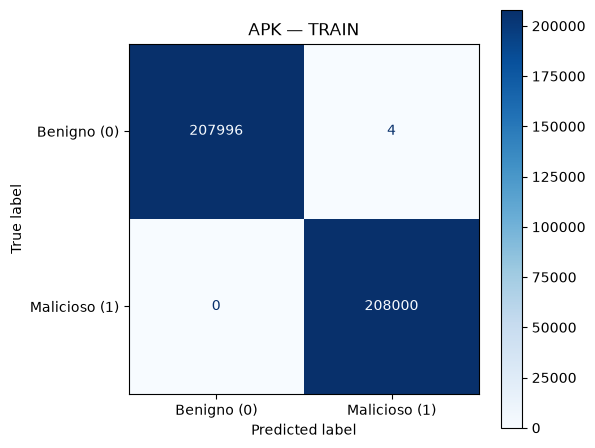

APK | TRAIN | VN=207996 FP=4 FN=0 VP=208000


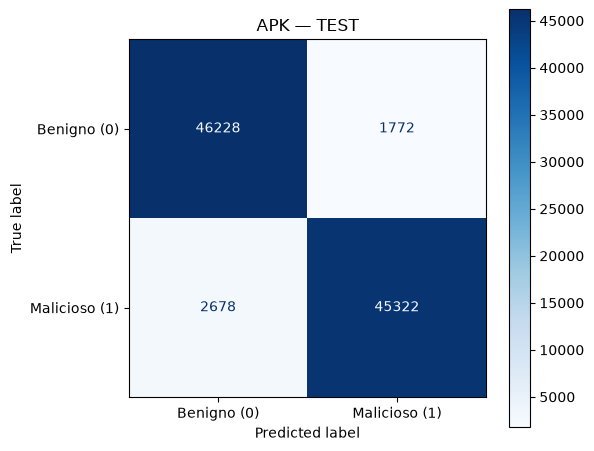

APK | TEST | VN=46228 FP=1772 FN=2678 VP=45322


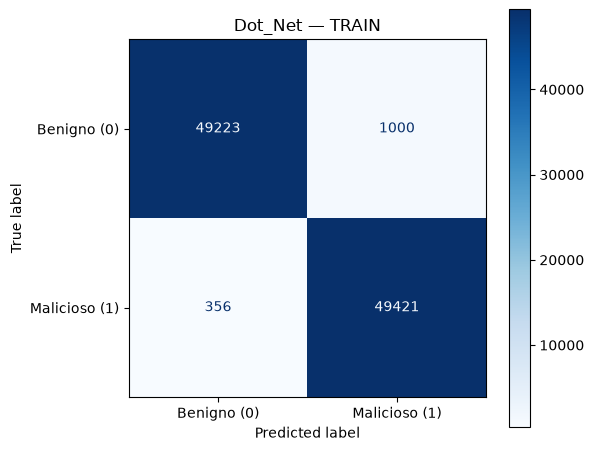

Dot_Net | TRAIN | VN=49223 FP=1000 FN=356 VP=49421


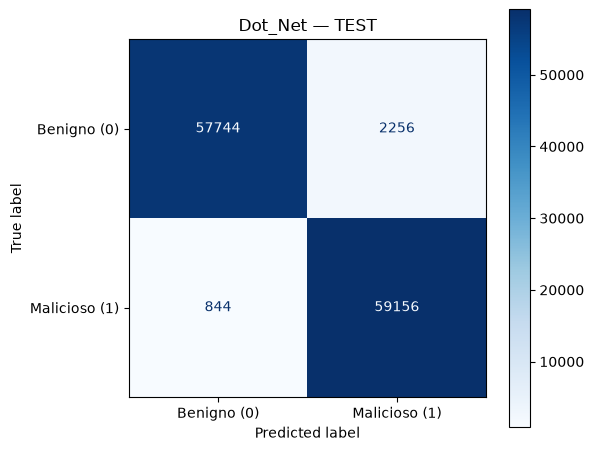

Dot_Net | TEST | VN=57744 FP=2256 FN=844 VP=59156


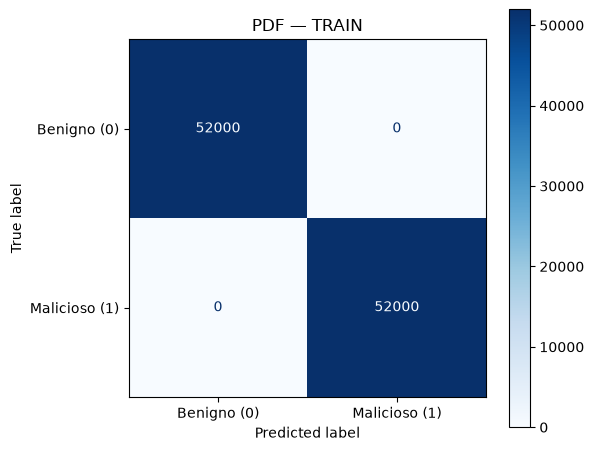

PDF | TRAIN | VN=52000 FP=0 FN=0 VP=52000


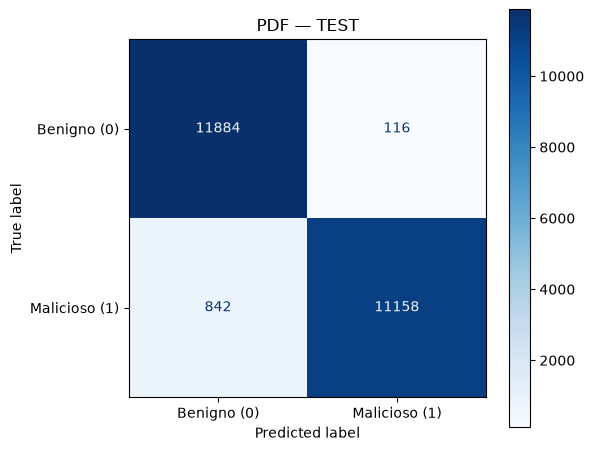

PDF | TEST | VN=11884 FP=116 FN=842 VP=11158


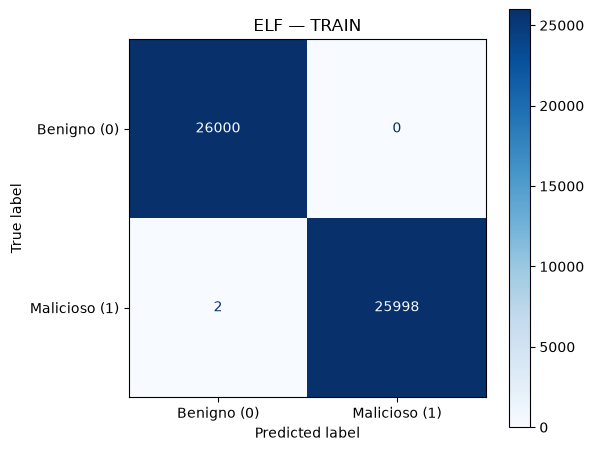

ELF | TRAIN | VN=26000 FP=0 FN=2 VP=25998


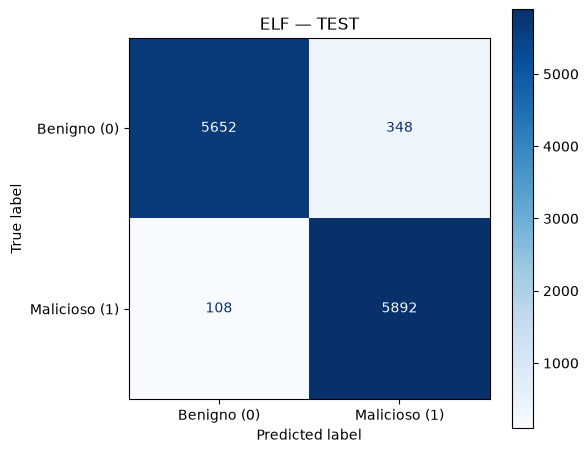

ELF | TEST | VN=5652 FP=348 FN=108 VP=5892

Resumo das matrizes de confusão:


,tipo,conjunto,n_amostras,verdadeiros_negativos,falsos_positivos,falsos_negativos,verdadeiros_positivos
0,APK,train,416000,207996,4,0,208000
1,APK,test,96000,46228,1772,2678,45322
2,Dot_Net,train,100000,49223,1000,356,49421
3,Dot_Net,test,120000,57744,2256,844,59156
4,PDF,train,104000,52000,0,0,52000
5,PDF,test,24000,11884,116,842,11158
6,ELF,train,52000,26000,0,2,25998
7,ELF,test,12000,5652,348,108,5892



Arquivos salvos em: d:\Iniciação Científica\ag_models\matrizes_confusao


In [12]:

# ================================================================
# CÉLULA 10 — Matrizes de confusão por tipo e conjunto
# ================================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

TIPOS = ["APK", "Dot_Net", "PDF", "ELF"]
CONJUNTOS = ["train", "test"]

RAIZ_MATRIZES = os.path.join(RAIZ_MODELOS, "matrizes_confusao")
os.makedirs(RAIZ_MATRIZES, exist_ok=True)

resultados_matrizes = []


def calcular_matriz_confusao(tipo, conjunto, predictor):
    destino = os.path.join(RAIZ_DADOS, tipo)

    X, y = thrember.read_vectorized_features(
        destino, subset=conjunto
    )

    y = np.asarray(y)
    idx = np.where(np.isin(y, [0, 1]))[0]

    X = np.asarray(X[idx], dtype=np.float32)
    y = y[idx].astype(int)

    # Mesmo limite de treino usado no experimento original
    if conjunto == "train":
        limite = N_TREINO.get(tipo)

        if limite is not None and len(y) > limite:
            rng_local = np.random.default_rng(SEED)
            idx_amostra = np.sort(
                rng_local.choice(
                    len(y), size=limite, replace=False
                )
            )
            X = X[idx_amostra]
            y = y[idx_amostra]

    colunas = [f"feat_{i}" for i in range(X.shape[1])]
    df = pd.DataFrame(X, columns=colunas)

    proba = predictor.predict_proba(
        df, as_multiclass=False
    ).to_numpy()

    y_pred = (proba >= THRESHOLD).astype(int)

    # Ordem fixa: classe 0 = benigno; classe 1 = malicioso
    cm = confusion_matrix(y, y_pred, labels=[0, 1])

    vn, fp, fn, vp = cm.ravel()

    # Salvar a imagem da matriz
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benigno (0)", "Malicioso (1)"]
    )
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"{tipo} — {conjunto.upper()}")
    plt.tight_layout()

    nome_imagem = f"matriz_{tipo}_{conjunto}.png"
    fig.savefig(
        os.path.join(RAIZ_MATRIZES, nome_imagem),
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    resultado = {
        "tipo": tipo,
        "conjunto": conjunto,
        "n_amostras": len(y),
        "verdadeiros_negativos": int(vn),
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn),
        "verdadeiros_positivos": int(vp),
    }

    print(
        f"{tipo} | {conjunto.upper()} | "
        f"VN={vn} FP={fp} FN={fn} VP={vp}"
    )

    return resultado


# Avaliar os modelos individuais das células 3 a 6
for tipo in TIPOS:
    caminho_modelo = os.path.join(RAIZ_MODELOS, tipo)

    if not os.path.exists(caminho_modelo):
        print(f"Modelo não encontrado: {tipo}. Pulando.")
        continue

    predictor = TabularPredictor.load(caminho_modelo)

    for conjunto in CONJUNTOS:
        resultado = calcular_matriz_confusao(
            tipo, conjunto, predictor
        )
        resultados_matrizes.append(resultado)

    del predictor
    gc.collect()


# Exportar tabela consolidada
df_matrizes = pd.DataFrame(resultados_matrizes)

caminho_csv = os.path.join(
    RAIZ_MATRIZES, "resumo_matrizes_confusao.csv"
)
df_matrizes.to_csv(caminho_csv, index=False)

print("\nResumo das matrizes de confusão:")
display(df_matrizes)

print(f"\nArquivos salvos em: {RAIZ_MATRIZES}")
